In [1]:
words = open('names.txt','r').read().splitlines()

In [2]:
words[:5]

['emma', 'olivia', 'ava', 'isabella', 'sophia']

In [3]:
len(words)

32033

In [4]:
min(len(w) for w in words)

2

In [5]:
max(len(w) for w in words)

15

In [6]:
b = {}
for w in words:
  chars = ['<S>'] + list(w) + ['<E>']
  for char1, char2 in zip(chars, chars[1:]):
    bigram = (char1, char2)
    b[bigram] = b.get(bigram, 0) + 1
# dict of frequency of pairs of consecutive characters (including cases where both characters are the same

In [7]:
sorted(b.items(), key=lambda kv: kv[1], reverse=True)[:10]

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963)]

In [8]:
import torch

In [10]:
chars = sorted(list(set(''.join(words)))) # ['a', 'b', 'c', 'd', 'e' ...]
stoi = {s:i+1 for i,s in enumerate(chars)} # {'a': 1, 'b': 2 ...
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()} # {1: 'a', 2: 'b', 3: 'c'  ...

In [20]:
# so here we fill the matrix
# N[i, j] = how often char i is followed by char j
N = torch.zeros((28,28), dtype=torch.int32)

for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2] += 1


N[:3, :3] #the first squere in heatmap

tensor([[   0, 4410, 1306],
        [6640,  556,  541],
        [ 114,  321,   38]], dtype=torch.int32)

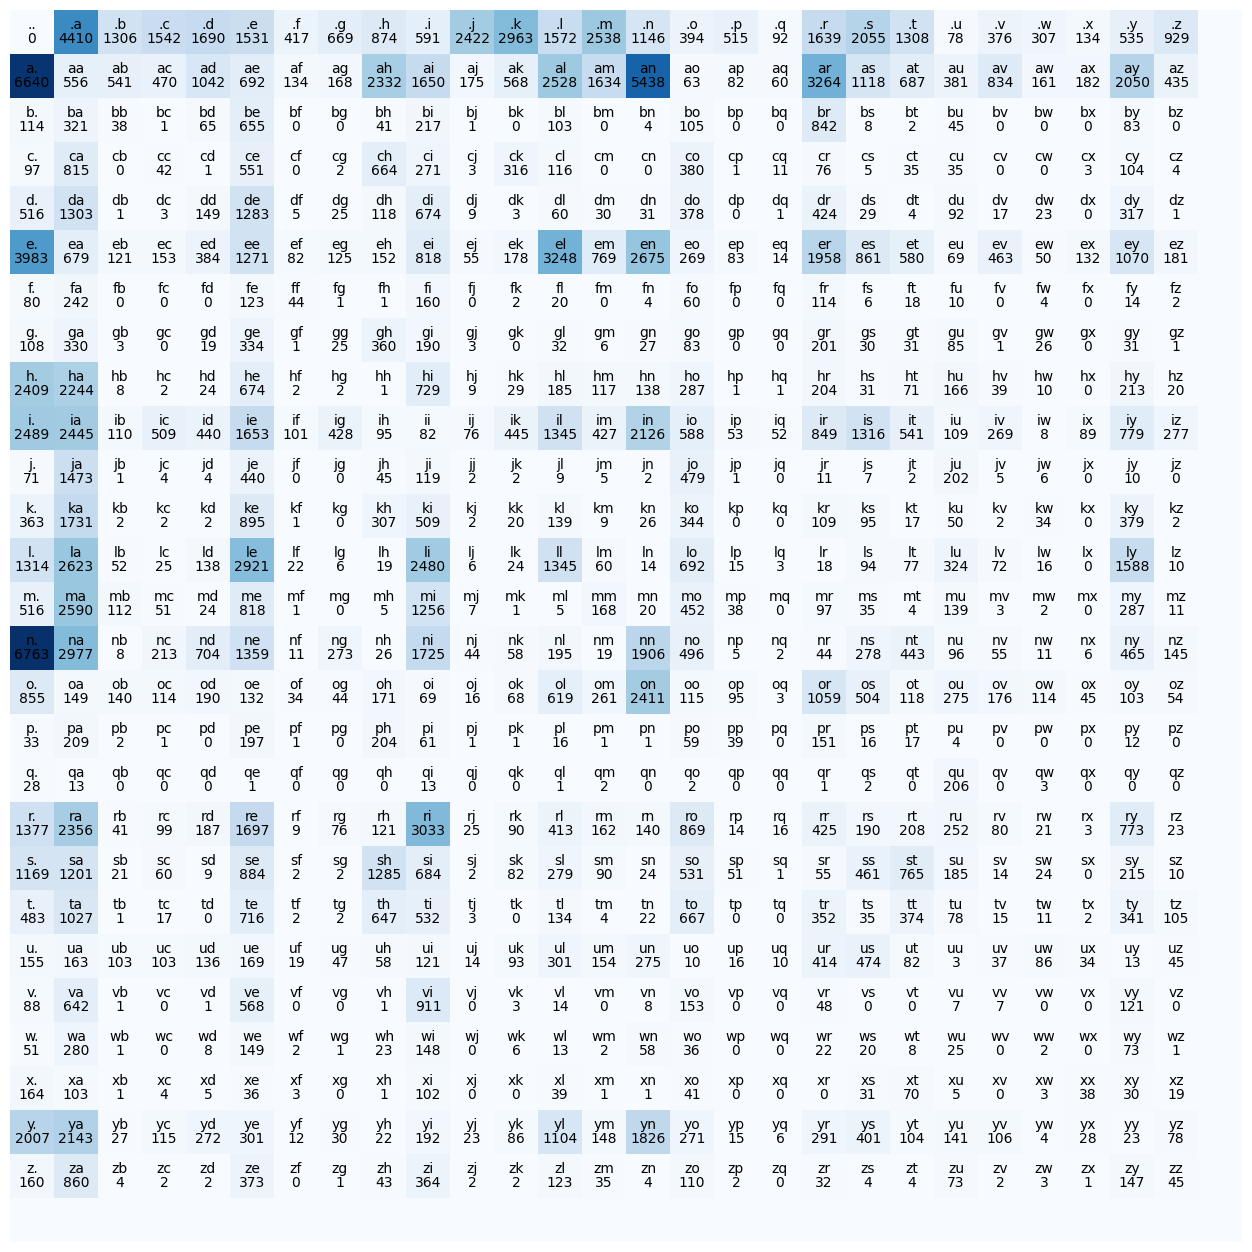

In [12]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='black')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='black')
plt.axis('off');
plt.show()